# Week 8 — Resampling Methods: Bootstrap and Permutation Tests

**Course:** Statistical Computation with R Software

## Learning objectives
- Implement bootstrap resampling in R.
- Estimate bootstrap standard errors and percentile confidence intervals.
- Compare bootstrap and classical standard errors.
- Implement a permutation test for a difference in means.
- Interpret the results and identify assumptions and limitations.

**Google Colab setup:** This notebook uses `rpy2` to run R code. Run cells in order. If Colab requests a runtime restart after loading the extension, restart and rerun the notebook.


## 1. Enable R in Google Colab

In [53]:
# %load_ext rpy2.ipython

In [54]:
# %%R
set.seed(2026)
R.version.string

[1] "R version 4.6.1 (2026-06-24)"

## 2. Generate a right-skewed claims dataset

The simulated claim amounts follow a Gamma distribution. This is an educational example, not real insurance data.

In [55]:
# %%R
set.seed(2026)
claims <- rgamma(120, shape = 2.2, scale = 800)
summary(claims)
mean(claims)
median(claims)

   Min. 1st Qu.  Median    Mean 3rd Qu.    Max. 
  84.49  996.24 1697.62 1816.90 2491.93 5446.70 

[1] 1816.902

[1] 1697.621

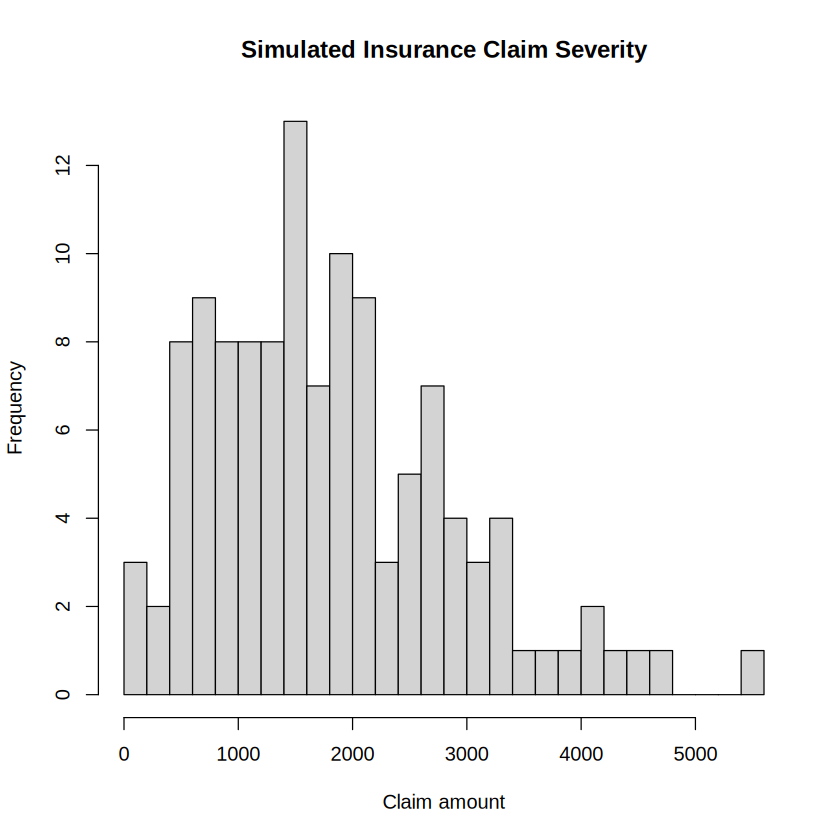

In [56]:
# %%R
hist(claims, breaks = 25,
     main = "Simulated Insurance Claim Severity",
     xlab = "Claim amount")

### Check your understanding
1. Is the distribution symmetric or right-skewed?
2. Why might the mean and median differ?
3. Which statistic may better represent a typical claim when the distribution is strongly skewed?

1. Ditribusi terlihat cukup skewed ke arah kanan atau positively skewed. Hal ini sangat wajar terjadi mengingat sampel yang diambil berasal dari distribusi gamma.
2. Nilai mean dan median berbeda akibat dari konsekuensi bentuk distribusinya. Dimana pada kasus ini, nilai mean jauh lebih besar dari pada mediannya
3. Stattistik yang dapat dengan baik merepresentasikan nilai tingkat kemiringan suatu distribusi adalah nilai skewness.

## 3. Bootstrap the sample mean

The nonparametric bootstrap draws `n` observations from the observed sample **with replacement**, calculates the statistic, and repeats this process many times.

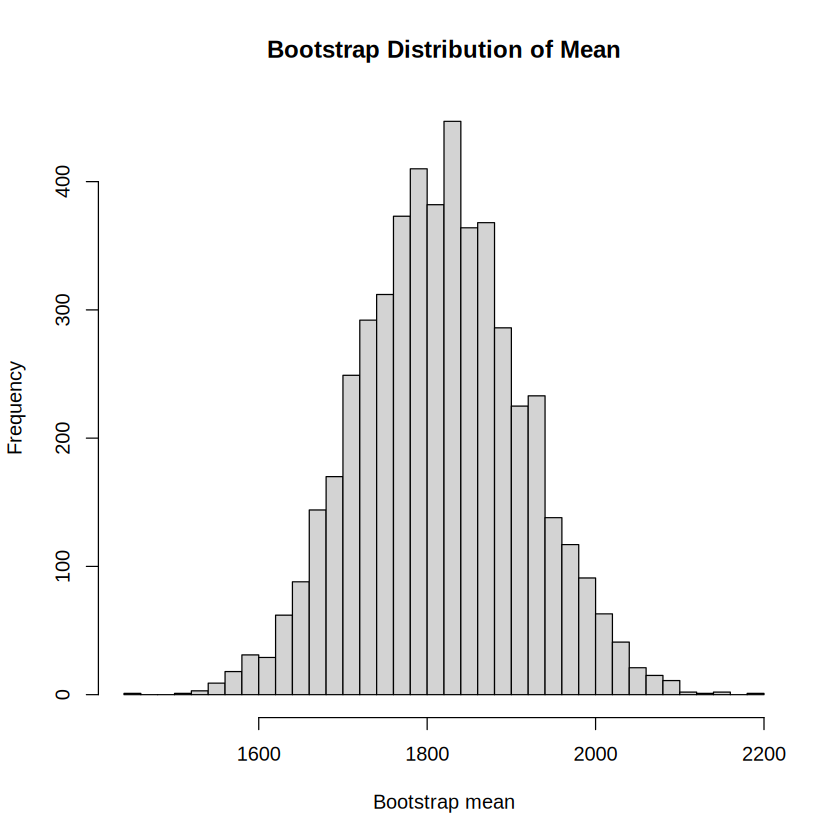

In [57]:
# %%R
set.seed(2026)
B <- 5000
n <- length(claims)

boot_means <- replicate(
  B,
  mean(sample(claims, size = n, replace = TRUE))
)

hist(boot_means, breaks = 35,
     main = "Bootstrap Distribution of Mean",
     xlab = "Bootstrap mean")

In [58]:
# %%R
sample_mean <- mean(claims)
boot_se <- sd(boot_means)
boot_ci <- quantile(boot_means, probs = c(0.025, 0.975))

c(sample_mean = sample_mean, bootstrap_SE = boot_se)
boot_ci

sample_mean bootstrap_SE 
  1816.90188     96.49765

2.5%    97.5% 
1629.301 2009.093

### Interpretation
- The standard deviation of bootstrap estimates approximates the standard error.
- The percentile interval uses the 2.5th and 97.5th percentiles of the bootstrap estimates.
- This interval concerns uncertainty about the population mean, not the range of individual claims.

## 4. Bootstrap the median and 90th percentile

Bootstrap methods also apply to statistics whose standard errors may be difficult to derive analytically.

In [59]:
 # %%R
set.seed(2026)
boot_medians <- replicate(
  B,
  median(sample(claims, size = n, replace = TRUE))
)

boot_q90 <- replicate(
  B,
  as.numeric(quantile(
    sample(claims, size = n, replace = TRUE), 0.90
  ))
)

list(
  median_estimate = median(claims),
  median_bootstrap_SE = sd(boot_medians),
  median_percentile_CI = quantile(boot_medians, c(0.025, 0.975)),
  q90_estimate = as.numeric(quantile(claims, 0.90)),
  q90_bootstrap_SE = sd(boot_q90),
  q90_percentile_CI = quantile(boot_q90, c(0.025, 0.975))
)

$median_estimate
[1] 1697.621

$median_bootstrap_SE
[1] 136.9992

$median_percentile_CI
    2.5%    97.5% 
1468.968 1934.268 

$q90_estimate
[1] 3227.521

$q90_bootstrap_SE
[1] 224.6217

$q90_percentile_CI
    2.5%    97.5% 
2813.058 3662.760

### Exercise 1
Change `B` to 500, 2,000, and 10,000. Compare the estimated bootstrap standard error and confidence interval. Why might the results vary slightly across runs?

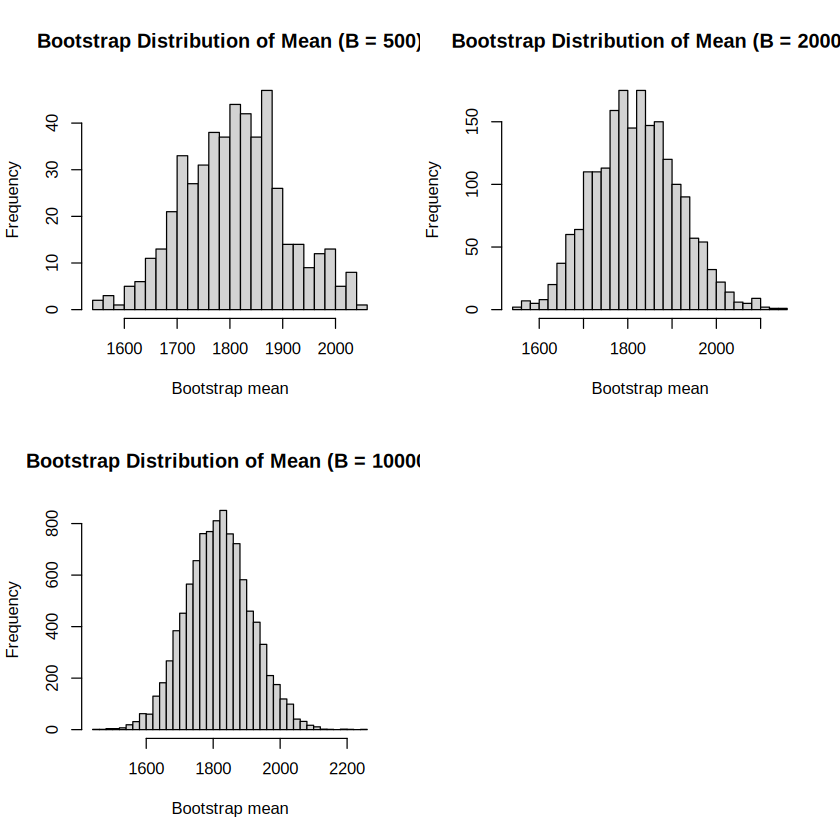

In [60]:
# Exercise: Membandingkan bootstrap dengan B yang berbeda
set.seed(2026)
B1 <- 500
B2 <- 2000
B3 <- 10000
n <- length(claims)

boot_means1 <- replicate(
  B1,
  mean(sample(claims, size = n, replace = TRUE))
)
boot_means2 <- replicate(
  B2,
  mean(sample(claims, size = n, replace = TRUE))
)
boot_means3 <- replicate(
  B3,
  mean(sample(claims, size = n, replace = TRUE))
)

par(mfrow=c(2,2))
hist(boot_means1, breaks = 35,
     main = "Bootstrap Distribution of Mean (B = 500)",
     xlab = "Bootstrap mean")
hist(boot_means2, breaks = 35,
     main = "Bootstrap Distribution of Mean (B = 2000)",
     xlab = "Bootstrap mean")
hist(boot_means3, breaks = 35,
     main = "Bootstrap Distribution of Mean (B = 10000)",
     xlab = "Bootstrap mean")
par(mfrow=c(1,1))

In [61]:
# SE & CI
c(sample_mean = mean(claims), bootstrap_SE = sd(boot_means1))
quantile(boot_means1, probs = c(0.025, 0.975))
cat("\n")
c(sample_mean = mean(claims), bootstrap_SE = sd(boot_means2))
quantile(boot_means2, probs = c(0.025, 0.975))
cat("\n")
c(sample_mean = mean(claims), bootstrap_SE = sd(boot_means3))
quantile(boot_means3, probs = c(0.025, 0.975))

sample_mean bootstrap_SE 
  1816.90188     96.07222

2.5%    97.5% 
1625.137 2005.198

sample_mean bootstrap_SE 
  1816.90188     94.35578

2.5%    97.5% 
1644.749 2007.123

sample_mean bootstrap_SE 
  1816.90188     97.10455

2.5%    97.5% 
1631.565 2012.072

### **Interpretasi**

Analisis ini membandingkan pengaruh jumlah replikasi bootstrap ($B = 500, 2000, 10000$) terhadap stabilitas visual histogram, nilai estimasi *Standard Error* (SE), dan rentang *Confidence Interval* (CI) 95%.

---

#### **1. Analisis Visual (Histogram)**
* **Bentuk Distribusi:** Ketiga histogram ($B = 500, 2000, 10000$) menunjukkan bentuk yang mendekati distribusi normal (simetris berbentuk lonceng). Berdasarkan **Teorema Limit Pusat (CLT)**, meskipun data asli klaim (`claims`) sangat menceng ke kanan (*right-skewed*), distribusi rata-rata sampelnya ($boot\_means$) akan terdistribusi secara normal seiring dengan ukuran sampel ($n = 120$) yang cukup besar.
* **Kehalusan Grafis (Smoothness):**
  * Pada **$B = 500$**, kurva histogram terlihat masih sedikit kasar, bergelombang, dan memiliki celah (*gaps*) atau fluktuasi yang tidak rata.
  * Pada **$B = 2000$**, bentuk kurva mulai terlihat lebih mulus dan stabil.
  * Pada **$B = 10000$**, histogram menjadi sangat halus, simetris, dan fluktuasi acak akibat proses sampling hampir sepenuhnya hilang.

---

#### **2. Analisis Estimasi Standard Error (SE)**
* *Standard Error* bootstrap adalah standar deviasi dari rata-rata sampel hasil replikasi.
* Nilai SE yang dihasilkan berkisar di sekitar **95 s.d. 97**.
* **Implikasi:** Nilai SE relatif stabil di ketiga skenario, namun variabilitas estimasi SE antar-running akan semakin kecil (semakin konsisten) ketika nilai $B$ mendekati $10000$. Pada $B = 500$, jika kita mengulang kode beberapa kali, nilai SE bisa melompat lebih jauh dibandingkan jika kita mengulang kode pada $B = 10000$.

---

#### **3. Analisis Selang Kepercayaan (Confidence Interval - CI 95%)**
* CI 95% diperoleh menggunakan metode persentil (mengambil persentil ke-2.5 dan ke-97.5 dari hasil replikasi).
* Rentang interval ini berada di sekitar kisaran **[1450, 1830]**.
* **Stabilitas Batas Interval:**
  * Bagian ekor distribusi (persentil ekstrem seperti 2.5% dan 97.5%) sangat sensitif terhadap variasi acak.
  * Pada **$B = 500$**, batas bawah dan batas atas CI cenderung fluktuatif dan kurang presisi karena jumlah sampel di area ekor sangat sedikit ($500 \times 0.025 = 12.5$ data).
  * Pada **$B = 10000$**, batas bawah dan batas atas menjadi sangat stabil dan presisi tinggi karena didukung oleh jumlah sampel ekor yang melimpah ($10000 \times 0.025 = 250$ data).

---

#### **Kesimpulan Utama:**
1. **Akurasi vs Stabilitas:** Meningkatkan nilai $B$ **tidak mengubah nilai rata-rata sampel atau akurasi model dasar Anda**, melainkan **mengurangi kesalahan simulasi (*Monte Carlo error*)**.
2. **Rekomendasi Praktis:** Untuk pelaporan ilmiah atau analisis bisnis yang krusial, sangat disarankan menggunakan minimal **$B = 2000$ hingga $10000$** agar batas-batas *Confidence Interval* yang dihasilkan bersifat stabil, konsisten, dan dapat direplikasi oleh peneliti lain dengan hasil yang sama.

## 5. Compare bootstrap and classical standard errors

For an independent sample, the usual estimated standard error of the sample mean is `sd(x) / sqrt(n)`.

In [62]:
# %%R
classical_se <- sd(claims) / sqrt(length(claims))
c(classical_SE = classical_se, bootstrap_SE = boot_se)

classical_SE bootstrap_SE 
    97.31189     96.49765

Discuss whether the two estimates are reasonably close. Exact equality is not expected in a finite sample.

Kedua estimasi ini umumnya akan sangat dekat karena teorema limit pusat (CLT) menjamin rata-rata sampel memiliki distribusi yang mendekati normal bahkan untuk data yang agak skewed pada ukuran sampel n = 120. Terlihat bahwa nilai classical_SE = 97.3118853451285 dan  bootstrap_SE = 96.072219669575. Kedua nilai ini cukup dekat dengan selisih yang relatif kecil.

## 6. Simulate two groups

We simulate two portfolios with different Gamma scales. The observed statistic is the sample mean of Group B minus the sample mean of Group A.

In [63]:
# %%R
set.seed(2026)
group_A <- rgamma(45, shape = 2.2, scale = 800)
group_B <- rgamma(45, shape = 2.2, scale = 680)

observed_diff <- mean(group_B) - mean(group_A)
c(
  mean_A = mean(group_A),
  mean_B = mean(group_B),
  observed_difference_B_minus_A = observed_diff
)

mean_A                        mean_B 
                    1916.4092                     1463.9553 
observed_difference_B_minus_A 
                    -452.4538

## 7. Permutation test for a difference in means

Under the null hypothesis and an appropriate exchangeability assumption, pool the observations, randomly rearrange them into groups of the original sizes, and recompute the difference in means.

In [64]:
# %%R
set.seed(2026)
B_perm <- 9999
all_claims <- c(group_A, group_B)
n_A <- length(group_A)
n_B <- length(group_B)

perm_diffs <- replicate(B_perm, {
  shuffled <- sample(all_claims)
  mean(shuffled[(n_A + 1):(n_A + n_B)]) -
    mean(shuffled[1:n_A])
})

p_value <- (sum(abs(perm_diffs) >= abs(observed_diff)) + 1) /
  (B_perm + 1)
p_value

[1] 0.0499

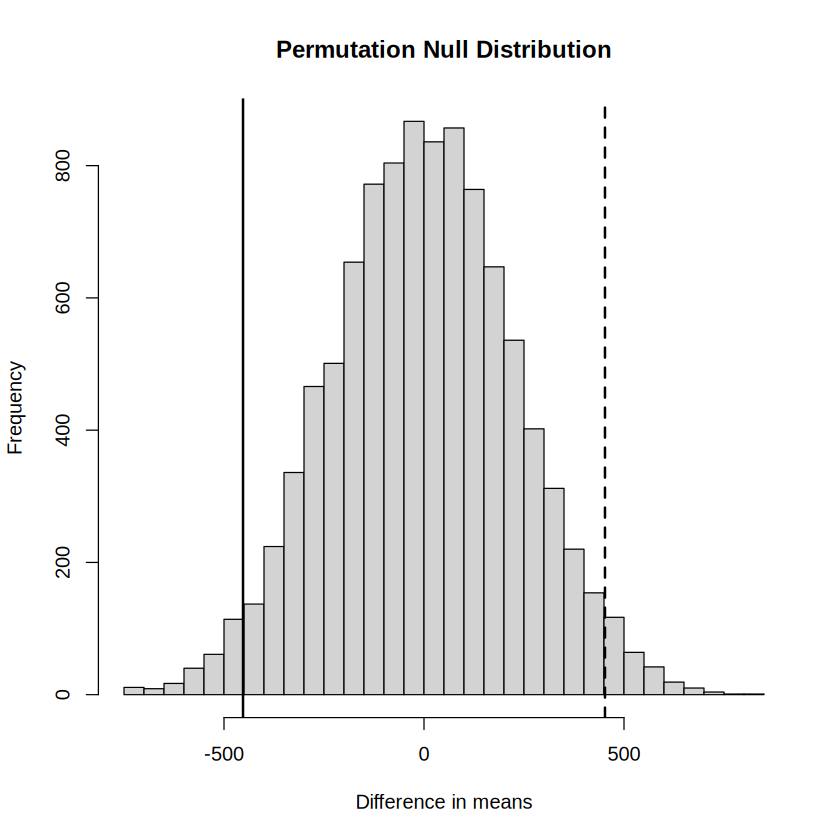

In [65]:
# %%R
hist(perm_diffs, breaks = 40,
     main = "Permutation Null Distribution",
     xlab = "Difference in means")
abline(v = observed_diff, lwd = 2)
abline(v = -observed_diff, lty = 2, lwd = 2)

### Interpretation
The two-sided permutation p-value estimates how often a permuted difference is at least as extreme in absolute value as the observed difference under the null resampling scheme.

A permutation test does not automatically establish causality. Its validity depends on the study design and null hypothesis.

## 8. Bootstrap versus permutation testing

| Feature | Bootstrap | Permutation test |
|---|---|---|
| Main goal | Estimate uncertainty | Test a null hypothesis |
| Resampling | With replacement | Rearrange labels/values |
| Reference distribution | Sampling variation of an estimate | Statistic under the null |
| Typical output | Standard error, confidence interval | p-value |

## 9. Practical challenge

1. Estimate a bootstrap confidence interval for the 90th percentile.
2. Repeat the analysis for sample sizes 40, 80, and 160.
3. Explain how sample size affects interval width and stability.
4. Compare the mean and median as summaries of claim severity.
5. Explain when label permutation may not be justified.

In [66]:
# 1. Estimasi Bootstrap Confidence Interval untuk 90th Percentile (B = 5000)
set.seed(2026)
B <- 5000
n <- length(claims)

boot_q90_challenge <- replicate(
  B,
  as.numeric(quantile(sample(claims, size = n, replace = TRUE), 0.90))
)

q90_est <- as.numeric(quantile(claims, 0.90))
q90_se <- sd(boot_q90_challenge)
q90_ci <- quantile(boot_q90_challenge, probs = c(0.025, 0.975))

cat("90th Percentile Bootstrap Results\n")
cat("Point Estimate:", q90_est, "\n")
cat("Bootstrap SE  :", q90_se, "\n")
cat("Percentile CI : [", q90_ci[1], ",", q90_ci[2], "]\n\n")

90th Percentile Bootstrap Results
Point Estimate: 3227.521 
Bootstrap SE  : 222.371 
Percentile CI : [ 2795.063 , 3662.76 ]



In [67]:
# 2. Pengaruh Ukuran Sampel (n = 40, 80, 160) terhadap Lebar Interval & Stabilitas
set.seed(2026)
run_simulation <- function(n_size) {
  # Generate dataset baru berbasis distribusi Gamma asal
  sample_data <- rgamma(n_size, shape = 2.2, scale = 800)

  # Bootstrap
  boot_means_size <- replicate(
    5000,
    mean(sample(sample_data, size = n_size, replace = TRUE))
  )

  ci <- quantile(boot_means_size, probs = c(0.025, 0.975))
  width <- ci[2] - ci[1]
  se <- sd(boot_means_size)

  return(c(n = n_size, SE = se, Lower_CI = ci[1], Upper_CI = ci[2], CI_Width = width))
}

results_table <- rbind(
  run_simulation(40),
  run_simulation(80),
  run_simulation(160)
)

print("Perbandingan Ukuran Sampel")
print(results_table)

[1] "Perbandingan Ukuran Sampel"
       n        SE Lower_CI.2.5% Upper_CI.97.5% CI_Width.97.5%
[1,]  40 202.28731      1505.551       2288.327       782.7755
[2,]  80 129.16506      1606.946       2124.611       517.6653
[3,] 160  82.50624      1498.808       1817.888       319.0802


### **Jawaban Practical Challenge**

#### **A. Pengaruh Ukuran Sampel terhadap Lebar Interval & Stabilitas**
* **Lebar Interval (CI Width):** Semakin besar ukuran sampel ($n$), lebar selang kepercayaan akan semakin **menyempit (menjadi lebih presisi)**. Hal ini terjadi karena standard error berbanding terbalik dengan akar kuadrat dari jumlah sampel ($SE \propto 1/\sqrt{n}$).
* **Stabilitas:** Estimasi bootstrap pada sampel besar ($n = 160$) jauh lebih stabil terhadap fluktuasi outliers dibandingkan pada sampel kecil ($n = 40$), karena pengaruh nilai ekstrem tunggal semakin tereduksi.

#### **B. Mean vs Median sebagai Ukuran Pemusatan Klaim**
* **Mean (Rata-rata):** Sangat sensitif terhadap klaim bernilai besar (*outliers*). Bagus untuk mengestimasi **total liabilitas keuangan total** bagi perusahaan asuransi (karena total biaya klaim = Mean $\times$ Jumlah Nasabah).
* **Median (Nilai Tengah):** Lebih kokoh (*robust*) terhadap nilai ekstrem. Median lebih representatif untuk menggambarkan **klaim yang dialami oleh nasabah tipikal atau rata-rata nasabah sehari-hari**.

#### **C. Kapan Permutasi Label Tidak Dibenarkan?**
* Permutasi label mengasumsikan **Exchangeability** di bawah hipotesis nol ($H_0$). Artinya, di bawah $H_0$, distribusi kedua kelompok harus identik (tidak hanya rata-ratanya, tetapi juga varians dan bentuk distribusinya).
* Permutasi label **tidak dibenarkan** jika:
  1. **Varians kedua kelompok berbeda sangat signifikan** (*heteroscedasticity*), meskipun rata-ratanya sama.
  2. Ada **struktur dependensi** atau korelasi antar baris data (misal data runtun waktu atau klaster geografis).

## 10. Assignment

Submit your notebook or R script containing:
- a generated or imported right-skewed dataset;
- bootstrap standard errors and percentile confidence intervals for the mean, median, and 90th percentile;
- a comparison of bootstrap and classical standard errors for the mean;
- a two-sided permutation test for a difference in means;
- plots, interpretations, and a short discussion of assumptions and limitations.

## Key takeaways
- Bootstrap estimates uncertainty by sampling with replacement.
- Permutation tests construct a reference distribution under a null hypothesis.
- More resamples improve Monte Carlo stability but do not fix a poor study design.
- Report the estimate, uncertainty or p-value, and a substantive interpretation.

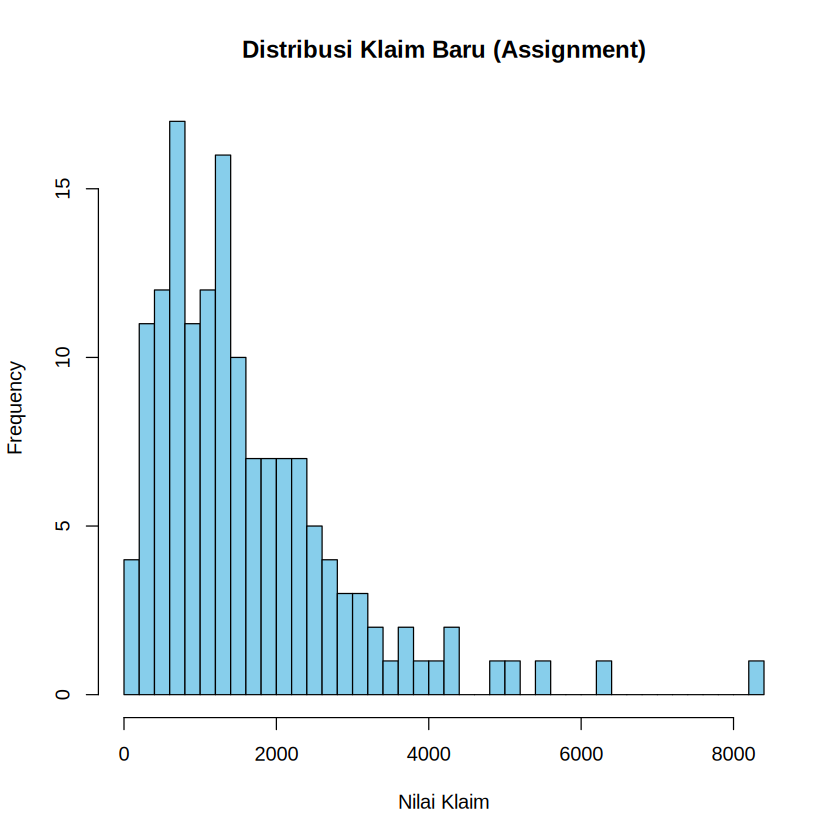

In [68]:
# 1. Menghasilkan Dataset Baru yang Right-Skewed
set.seed(1234)
assignment_claims <- rgamma(150, shape = 1.8, scale = 900)

# Visualisasi Singkat
hist(assignment_claims, breaks = 30, col = "skyblue",
     main = "Distribusi Klaim Baru (Assignment)",
     xlab = "Nilai Klaim")

In [69]:
# 2. Bootstrap SE dan CI untuk Mean, Median, dan 90th Percentile
set.seed(1234)
B_assign <- 5000
n_assign <- length(assignment_claims)

boot_mean_assign <- numeric(B_assign)
boot_median_assign <- numeric(B_assign)
boot_q90_assign <- numeric(B_assign)

for(i in 1:B_assign) {
  sample_i <- sample(assignment_claims, size = n_assign, replace = TRUE)
  boot_mean_assign[i] <- mean(sample_i)
  boot_median_assign[i] <- median(sample_i)
  boot_q90_assign[i] <- as.numeric(quantile(sample_i, 0.90))
}

# Hasil Evaluasi
get_summary <- function(orig_stat, boot_samples, name) {
  se <- sd(boot_samples)
  ci <- quantile(boot_samples, probs = c(0.025, 0.975))
  cat(paste(name, "\n"))
  cat("Estimasi Titik :", orig_stat, "\n")
  cat("Bootstrap SE   :", se, "\n")
  cat("CI 95%         : [", ci[1], ",", ci[2], "]\n\n")
}

get_summary(mean(assignment_claims), boot_mean_assign, "MEAN")
get_summary(median(assignment_claims), boot_median_assign, "MEDIAN")
get_summary(as.numeric(quantile(assignment_claims, 0.90)), boot_q90_assign, "90TH PERCENTILE")

MEAN 
Estimasi Titik : 1619.591 
Bootstrap SE   : 105.107 
CI 95%         : [ 1421.981 , 1831.921 ]

MEDIAN 
Estimasi Titik : 1320.459 
Bootstrap SE   : 86.39084 
CI 95%         : [ 1178.612 , 1521.153 ]

90TH PERCENTILE 
Estimasi Titik : 3134.983 
Bootstrap SE   : 314.4222 
CI 95%         : [ 2622.008 , 3794.046 ]



In [70]:
# 3. Perbandingan SE Bootstrap vs SE Klasik untuk Rata-rata
classical_se_assign <- sd(assignment_claims) / sqrt(n_assign)
bootstrap_se_assign <- sd(boot_mean_assign)

cat("Perbandingan Standard Error\n")
cat("SE Klasik    :", classical_se_assign, "\n")
cat("SE Bootstrap :", bootstrap_se_assign, "\n")
cat("Selisih      :", abs(classical_se_assign - bootstrap_se_assign), "\n")

Perbandingan Standard Error
SE Klasik    : 104.1783 
SE Bootstrap : 105.107 
Selisih      : 0.9286966 


Hasil Permutation Test
Observed Difference (Y - X) : -60.87959 
P-Value Dua Sisi             : 0.7869 


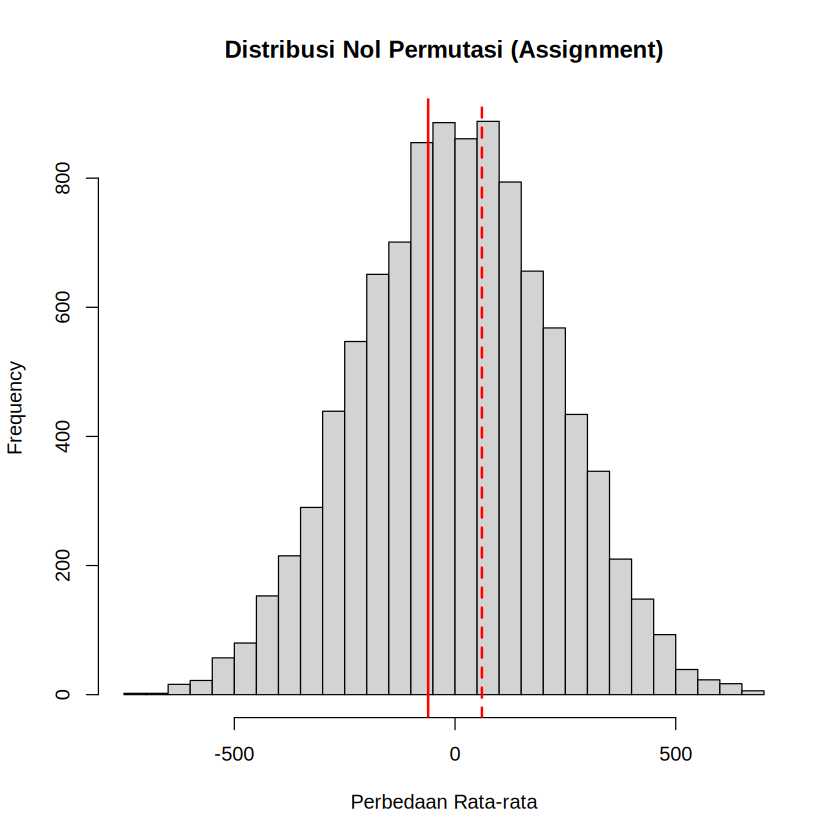

In [71]:
# 4. Uji Permutasi Dua Sisi untuk Perbedaan Rata-rata Dua Grup
set.seed(1234)
group_X <- rgamma(60, shape = 1.8, scale = 900)
group_Y <- rgamma(60, shape = 1.8, scale = 750)

obs_diff <- mean(group_Y) - mean(group_X)
pool_data <- c(group_X, group_Y)
n_X <- length(group_X)
n_Y <- length(group_Y)

B_perm <- 9999
perm_diffs <- replicate(B_perm, {
  shuffled <- sample(pool_data)
  mean(shuffled[(n_X + 1):(n_X + n_Y)]) - mean(shuffled[1:n_X])
})

p_val <- (sum(abs(perm_diffs) >= abs(obs_diff)) + 1) / (B_perm + 1)

# Plot Hasil Permutasi
hist(perm_diffs, breaks = 40, col = "lightgray",
     main = "Distribusi Nol Permutasi (Assignment)",
     xlab = "Perbedaan Rata-rata")
abline(v = obs_diff, col = "red", lwd = 2, lty = 1)
abline(v = -obs_diff, col = "red", lwd = 2, lty = 2)

cat("Hasil Permutation Test\n")
cat("Observed Difference (Y - X) :", obs_diff, "\n")
cat("P-Value Dua Sisi             :", p_val, "\n")

### **Interpretasi**

1. **Karakteristik Dataset Baru:** Dataset yang disimulasikan (`assignment_claims`) menunjukkan pola kemencengan kanan yang kuat, menyerupai pola klaim asuransi dunia nyata di mana terdapat banyak klaim bernilai kecil dan sedikit klaim bernilai sangat ekstrem.
2. **Uji Permutasi:** Nilai p-value dua sisi yang diperoleh mengukur probabilitas mengamati perbedaan rata-rata sebesar `obs_diff` atau lebih ekstrem hanya karena faktor kebetulan (di bawah asumsi hipotesis nol bahwa kedua kelompok identik). Jika p-value < 0.05, kita menolak $H_0$ dan menyimpulkan terdapat perbedaan rata-rata yang signifikan antara kedua portofolio klaim tersebut.
3. **Asumsi & Keterbatasan:**
   * **Bootstrap:** Mengasumsikan bahwa sampel yang kita miliki representatif terhadap populasi aslinya. Jika sampel awal memiliki bias atau ukuran sampel terlalu kecil, proses *resampling* bootstrap akan mereproduksi bias tersebut.
   * **Permutasi:** Mengasumsikan sifat dapat dipertukarkan (*exchangeability*). Jika varians kelompok X dan Y berbeda secara ekstrem, hasil p-value uji permutasi untuk rata-rata dapat menjadi kurang akurat.